# Axion field evolution and $\beta(z)$ as a function of mass

This notebook shows how the field $f=\phi/\phi_{\rm ini}$ and the rotation angle $\beta(z)$ depend on the axion mass $m$,
and checks the solver used by the modified CAMB (`camb.birefringence`).

**Contents**
1. Setup and the background $H(z)$ in eV
2. The equation, solved step by step by hand, compared with `camb.birefringence.solve_axion_field`
3. Check against the exact radiation-era and matter-era solutions
4. Field evolution for a list of masses 
5. $\beta(z)$ against the visibility function
6. Explore one mass: `explore(log_m)`
7. What CMB sees: EB spectra for a few masses

**The equation** (derived in section 2): with $x=\ln a$ and $' = d/dx$,
$$f'' + \left(3 + \frac{d\ln H}{d\ln a}\right) f' + \left(\frac{m}{H}\right)^2 f = 0,\qquad f(a_{\rm ini})=1,\ f'(a_{\rm ini})=0,$$
$$\beta(z) = \beta_{\rm ini}\,[f(z) - f(0)],\qquad \beta_{\rm ini} = -g\phi_{\rm ini}/2 .$$

## 1. Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.interpolate import CubicSpline
from scipy.special import jv, gamma
import camb
from camb.birefringence import solve_axion_field, axion_birefringence_table, hubble_ev

print("camb loaded from:", camb.__file__)

# cosmology used everywhere below: change it here
cosmo = dict(H0=67.5, ombh2=0.022, omch2=0.122, mnu=0.06, As=2e-9, ns=0.965, tau=0.055)
pars = camb.set_params(**cosmo, lmax=3000)
bg = camb.get_background(pars)          # background + thermal history (for the visibility function)

H0_ev = float(hubble_ev(bg, np.array([0.0]))[0])
print(f"H0 = {cosmo['H0']} km/s/Mpc = {H0_ev:.4e} eV")
print("A field starts to roll when m ~ H; it is still frozen today if m << H0 = %.1e eV" % H0_ev)

camb loaded from: /Users/debabrata/Documents/WORKS/WORKS/Cosmic_Birefringence/CAMB_BIREFRINGENCE_2.0.5/camb/__init__.py
H0 = 67.5 km/s/Mpc = 1.4398e-33 eV
A field starts to roll when m ~ H; it is still frozen today if m << H0 = 1.4e-33 eV


## 2. The equation, step by step

Start from $\ddot\phi + 3H\dot\phi + m^2\phi = 0$ (dots: cosmic time). With $x = \ln a$, $dx/dt = H$, so $d/dt = H\,d/dx$:
- $\dot\phi = H\phi'$
- $\ddot\phi = H\,(H\phi')' = H^2\phi'' + HH'\phi'$

Substituting and dividing by $H^2$ gives the equation above. Dividing by $\phi_{\rm ini}$ gives the same equation for $f$.
As two first-order equations, with $v = f'$:
$$f' = v,\qquad v' = -\left(3 + \frac{d\ln H}{d\ln a}\right)v - \left(\frac{m}{H}\right)^2 f .$$

Below, this is written out by hand for one mass and compared with the library function.

log m = -28.8: library stopped at z = 6.24 (m/H = 1000)
max |f_by_hand - f_library| before the stop: 0.0e+00
after the stop the hand solution oscillates with max |f| = 1.6e-03 (library: 0)


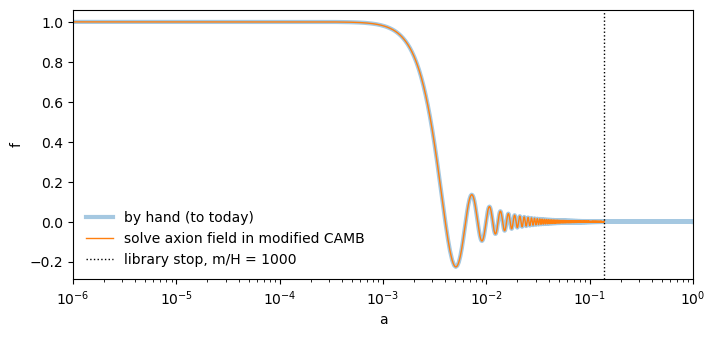

In [3]:
log_m = -28.8                      # try other values
m = 10**log_m                      # eV

# H(x) and d ln H / d ln a from CAMB, through a spline of ln H in x = ln a
x_grid = np.linspace(np.log(1e-8), 0.0, 6000)
lnH = CubicSpline(x_grid, np.log(hubble_ev(bg, np.exp(-x_grid) - 1)))
dlnH = lnH.derivative()

def rhs(x, y):
    f, v = y
    return [v, -(3 + dlnH(x)) * v - (m / np.exp(lnH(x)))**2 * f]

# integrate from a = 1e-8 to today (no early stop here, so every oscillation is followed)
mine = solve_ivp(rhs, (x_grid[0], 0.0), [1.0, 0.0], method="DOP853", rtol=1e-10, atol=1e-13,
                 dense_output=True, max_step=0.05)

# the library function (stops at m/H = 1000 and sets f = 0 afterwards)
lib, x_end, f0 = solve_axion_field(bg, m)

x = np.linspace(x_grid[0], x_end, 5000)
print(f"log m = {log_m}: library stopped at z = {np.exp(-x_end) - 1:.2f} (m/H = 1000)")
# same equation, same integrator and settings, so before the stop the two agree exactly (difference 0);
# they differ only after it, where the library sets f = 0 and the hand version follows the small oscillation
print(f"max |f_by_hand - f_library| before the stop: {np.max(np.abs(mine.sol(x)[0] - lib(x)[0])):.1e}")
xa = np.linspace(x_end, 0.0, 2000)
print(f"after the stop the hand solution oscillates with max |f| = {np.max(np.abs(mine.sol(xa)[0])):.1e} (library: 0)")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.semilogx(np.exp(mine.t), mine.y[0], lw=3, alpha=0.4, label="by hand (to today)")
ax.semilogx(np.exp(x), lib(x)[0], lw=1, label="solve axion field in modified CAMB")
ax.axvline(np.exp(x_end), color="k", ls=":", lw=1, label="library stop, m/H = 1000")
ax.set_xlabel("a"); ax.set_ylabel("f"); ax.set_xlim(1e-6, 1); ax.legend(frameon=False); plt.show()

## 3. Check: exact solutions

In a pure power-law background the equation has closed-form solutions with $f=1$, $f'=0$ initially:
- radiation ($H\propto a^{-2}$, $t = 1/2H$): $f = \Gamma(5/4)\,(u/2)^{-1/4} J_{1/4}(u)$, $u = mt = m/2H$
- matter ($H\propto a^{-3/2}$, $t = 2/3H$): $f = \sin u / u$, $u = mt = 2m/3H$
- Check out: arXiv:1510.07633
  
The solver is given a fake background whose $H(z)$ is an exact power law, chosen so that $m = H$ at $a = 10^{-4}$.

radiation: max |f - exact| = 2.9e-11
matter: max |f - exact| = 1.3e-11


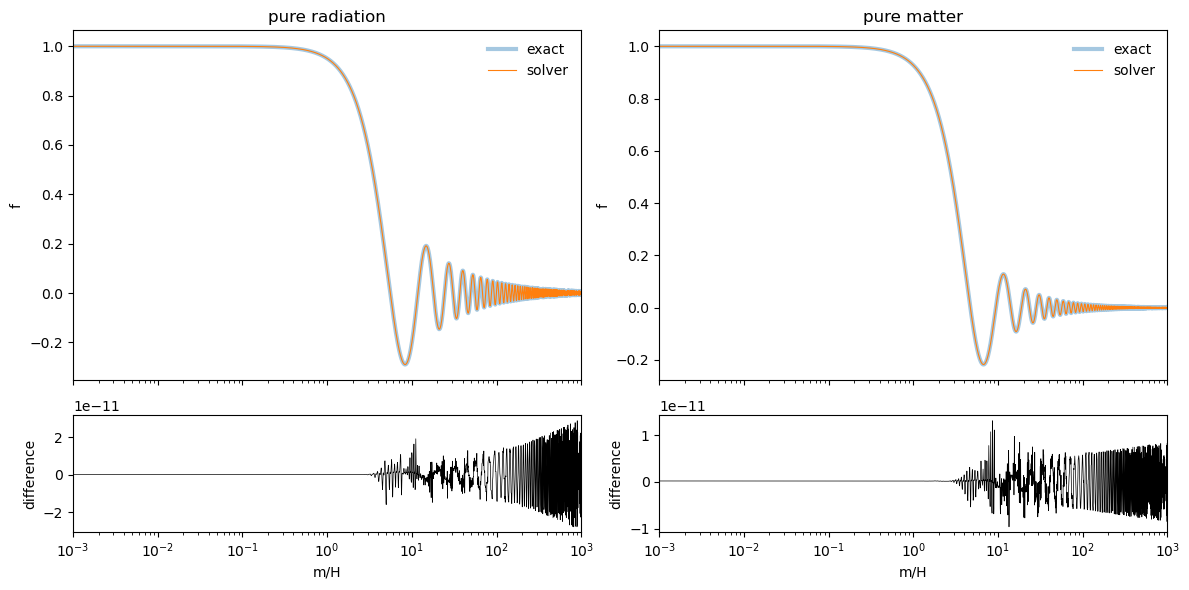

In [3]:
class PowerLaw:
    # stands in for a CAMB background: only hubble_parameter(z) in km/s/Mpc is needed
    def __init__(self, n, H_today): self.n, self.H_today = n, H_today
    def hubble_parameter(self, z): return self.H_today * (1 + np.asarray(z))**self.n

m_test = 1e-27
fig, ax = plt.subplots(2, 2, figsize=(12, 6), sharex=True, gridspec_kw=dict(height_ratios=[3, 1]))
for j, (n, name) in enumerate([(2, "radiation"), (1.5, "matter")]):
    bgp = PowerLaw(n, 1.0)
    bgp.H_today = m_test / float(hubble_ev(bgp, np.array([0.0]))[0]) / 1e4**n
    s, xe, _ = solve_axion_field(bgp, m_test)
    xx = np.linspace(np.log(1e-8), xe, 4000); f = s(xx)[0]
    mH = m_test / hubble_ev(bgp, np.exp(-xx) - 1)
    exact = gamma(1.25) * (mH / 4)**-0.25 * jv(0.25, mH / 2) if n == 2 else np.sin(2 * mH / 3) / (2 * mH / 3)
    print(f"{name}: max |f - exact| = {np.max(np.abs(f - exact)):.1e}")
    ax[0, j].semilogx(mH, exact, lw=3, alpha=0.4, label="exact"); ax[0, j].semilogx(mH, f, lw=0.8, label="solver")
    ax[0, j].set_title(f"pure {name}"); ax[0, j].legend(frameon=False); ax[0, j].set_ylabel("f")
    ax[1, j].semilogx(mH, f - exact, "k", lw=0.5); ax[1, j].set_xlabel("m/H"); ax[1, j].set_ylabel("difference")
    ax[1, j].set_xlim(1e-3, 1e3)
plt.tight_layout(); plt.show()

## 4. Field evolution for a list of masses

Edit `masses` (values of $\log_{10}(m/{\rm eV})$). For each mass the table gives where $m = H$ (the field starts to roll),
where the integration stops ($m/H = 1000$), $f$ today, and $\beta$ at recombination and reionization for $\beta_{\rm ini}$.

 log10 m | m/H0     | z(m=H)    | z(stop)  | f(0)      | beta(1090) | beta(10)   | beta(1)  [deg]
  -35.00 |  6.9e-03 |     never |    never | +1.00e+00 | +2.326e-06 | +2.323e-06 | +1.880e-06
  -33.00 |  6.9e-01 |     never |    never | +9.35e-01 | +2.278e-02 | +2.275e-02 | +1.834e-02
  -32.00 |  6.9e+00 |       4.3 |    never | +2.46e-02 | +3.414e-01 | +3.385e-01 | +3.892e-02
  -31.00 |  6.9e+01 |      23.7 |    never | +1.21e-03 | +3.496e-01 | +1.211e-01 | +4.348e-03
  -30.00 |  6.9e+02 |     112.8 |    never | -9.81e-04 | +3.503e-01 | -6.618e-03 | +1.299e-03
  -28.80 |  1.1e+04 |     682.4 |     6.24 | +0.00e+00 | +3.449e-01 | -5.499e-04 | +0.000e+00
  -27.90 |  8.7e+04 |    2418.9 |    27.81 | +0.00e+00 | +1.046e-01 | +0.000e+00 | +0.000e+00
  -27.80 |  1.1e+05 |    2768.4 |    32.57 | +0.00e+00 | +1.795e-02 | +0.000e+00 | +0.000e+00
  -27.70 |  1.4e+05 |    3161.7 |    38.12 | +0.00e+00 | -5.909e-02 | +0.000e+00 | +0.000e+00
  -27.00 |  6.9e+05 |    7766.1 |   112.82 | +0.00e+00 |

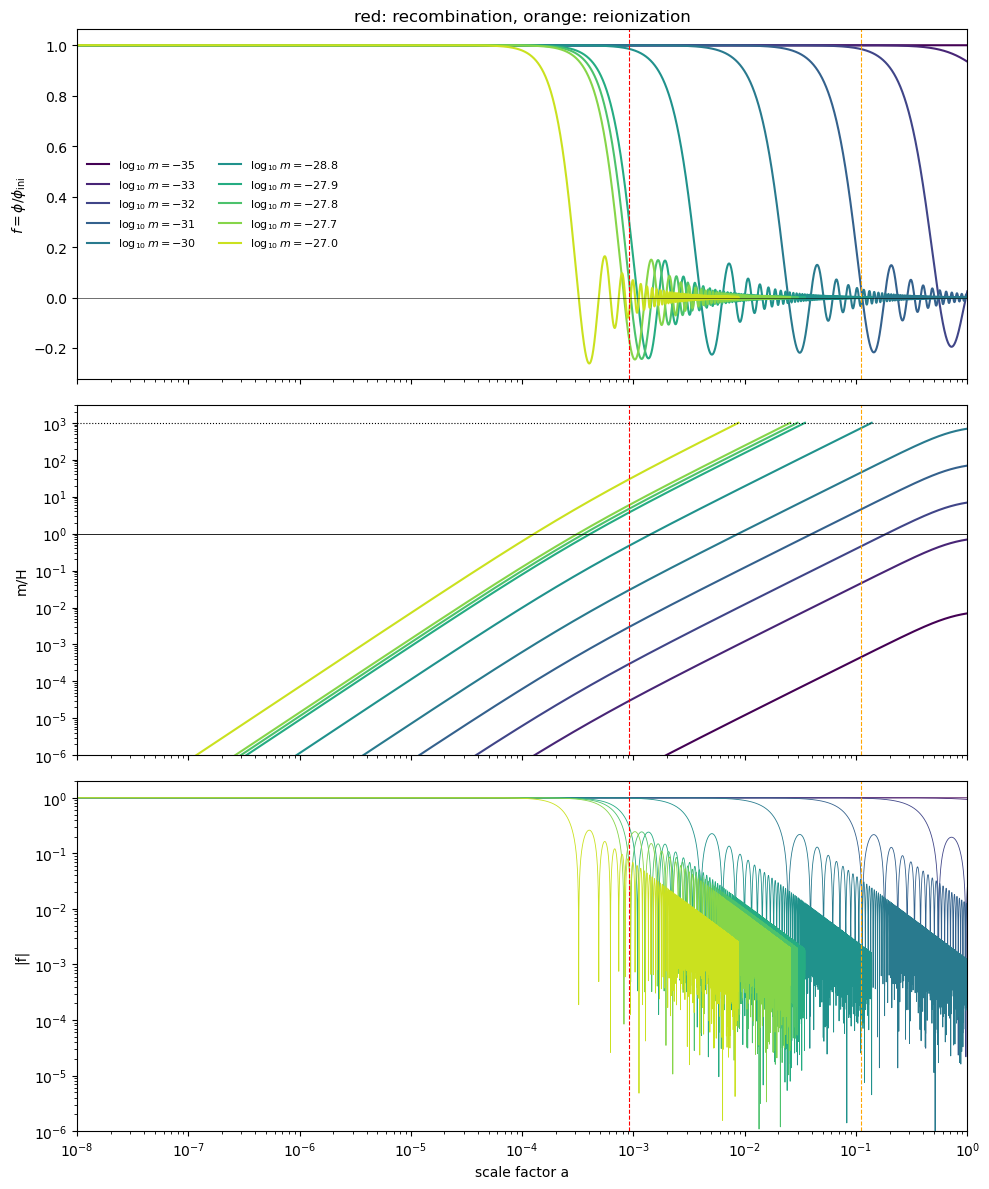

In [4]:
masses = [-35, -33, -32, -31, -30, -28.8, -27.9, -27.8, -27.7, -27.0]
beta_ini = 0.35   # degrees

cmap = plt.cm.viridis(np.linspace(0, 0.92, len(masses)))
sols = {}
print(" log10 m | m/H0     | z(m=H)    | z(stop)  | f(0)      | beta(1090) | beta(10)   | beta(1)  [deg]")
for lm in masses:
    s, xe, f0 = solve_axion_field(bg, 10**lm)
    xx = np.linspace(np.log(1e-8), xe, 20000)
    mH = 10**lm / hubble_ev(bg, np.exp(-xx) - 1)
    z_roll = f"{np.exp(-xx[np.argmax(mH > 1)]) - 1:9.1f}" if mH[-1] > 1 else "    never"
    z, b = axion_birefringence_table(pars, 10**lm, beta_ini, results=bg)
    sols[lm] = dict(x=xx, f=s(xx)[0], fp=s(xx)[1], mH=mH, z=z, beta=b, xe=xe, f0=f0)
    z_stop = f"{np.exp(-xe) - 1:8.2f}" if xe < -1e-12 else "   never"
    print(f" {lm:7.2f} | {10**lm / H0_ev:8.1e} | {z_roll} | {z_stop} | {f0:+.2e} |"
          f" {np.interp(1090, z, b):+.3e} | {np.interp(10, z, b):+.3e} | {np.interp(1, z, b):+.3e}")

a_rec, a_rei = 1 / 1091, 1 / 9
fig, ax = plt.subplots(3, 1, figsize=(10, 12), sharex=True)
for c, lm in zip(cmap, masses):
    d = sols[lm]; a = np.exp(d["x"])
    ax[0].semilogx(a, d["f"], color=c, label=rf"$\log_{{10}} m = {lm}$")
    ax[1].loglog(a, d["mH"], color=c)
    ax[2].loglog(a, np.abs(d["f"]), color=c, lw=0.6)
for a_ in ax:
    a_.axvline(a_rec, color="r", ls="--", lw=0.8); a_.axvline(a_rei, color="orange", ls="--", lw=0.8)
ax[0].set_ylabel(r"$f=\phi/\phi_{\rm ini}$"); ax[0].legend(frameon=False, fontsize=8, ncol=2); ax[0].axhline(0, color="k", lw=0.4)
ax[0].set_title("red: recombination, orange: reionization")
ax[1].axhline(1, color="k", lw=0.6); ax[1].axhline(1000, color="k", ls=":", lw=0.8); ax[1].set_ylabel("m/H"); ax[1].set_ylim(1e-6, 3e3)
ax[2].set_ylabel("|f|"); ax[2].set_ylim(1e-6, 2); ax[2].set_xlabel("scale factor a"); ax[2].set_xlim(1e-8, 1)
plt.tight_layout(); plt.show()

Reading the plots: a mass with $m \ll H_0$ (here $10^{-35}$, $10^{-33}$ eV) is still frozen today, so $f(z) - f(0)$ and
$\beta$ are tiny ($\propto (m/H_0)^2$). A mass that rolls between recombination and today ($10^{-32}$ to $10^{-29}$ eV) gives the
full $\beta_{\rm ini}$ to recombination photons. A mass that rolls before or during recombination ($\gtrsim 10^{-28}$ eV) gives
an oscillating $\beta$ across the last-scattering surface.

## 5. $\beta(z)$ against the visibility function

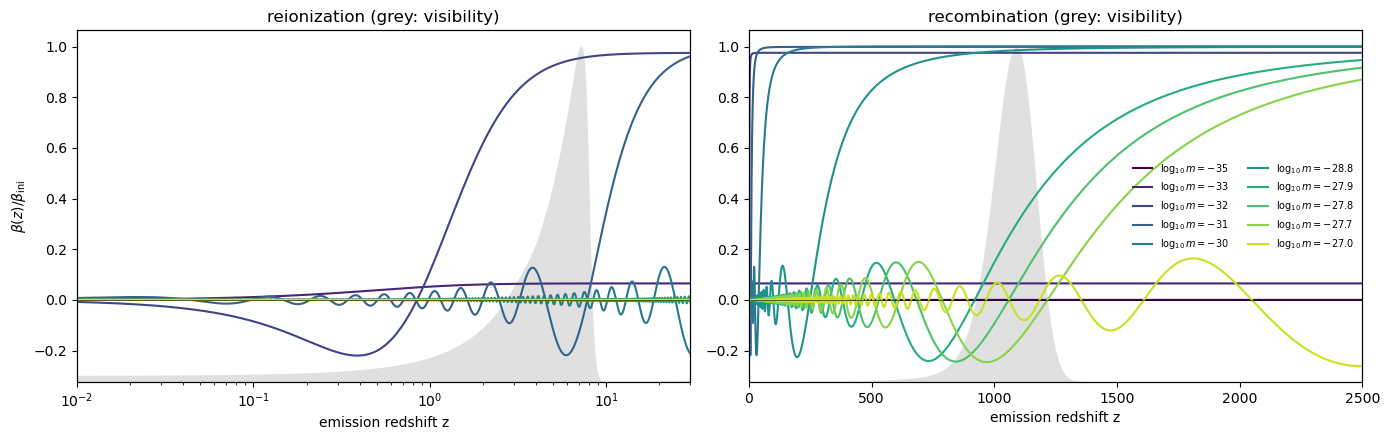

In [5]:
zz = np.linspace(0, 2500, 4000)
vis = bg.get_background_time_evolution(bg.conformal_time(zz), ["visibility"])["visibility"]
zl = np.logspace(-2, np.log10(30), 2000)
vis_low = bg.get_background_time_evolution(bg.conformal_time(zl), ["visibility"])["visibility"]

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for a_, zg, vg, xs in [(ax[0], zl, vis_low, "log"), (ax[1], zz, vis, "linear")]:
    tw = a_.twinx(); tw.fill_between(zg, vg / vg.max(), color="0.88"); tw.set_yticks([]); tw.set_ylim(0, 1.05)
    a_.set_zorder(tw.get_zorder() + 1); a_.patch.set_visible(False)
    for c, lm in zip(cmap, masses):
        d = sols[lm]; a_.plot(d["z"], d["beta"] / beta_ini, color=c, label=rf"$\log_{{10}} m = {lm}$")
    a_.set_xscale(xs); a_.axhline(0, color="k", lw=0.4); a_.set_xlabel("emission redshift z")
ax[0].set_xlim(1e-2, 30); ax[0].set_title("reionization (grey: visibility)"); ax[0].set_ylabel(r"$\beta(z)/\beta_{\rm ini}$")
ax[1].set_xlim(0, 2500); ax[1].set_title("recombination (grey: visibility)"); ax[1].legend(frameon=False, fontsize=7, ncol=2)
plt.tight_layout(); plt.show()

## 6. Explore one mass

Call `explore(log_m)` with any $\log_{10}(m/{\rm eV})$. It plots $f$, $f'$, $m/H$ and $\beta(z)$ and prints the key numbers.
If `ipywidgets` is installed, a slider is shown as well.

log m = -30.0: m/H0 = 6.95e+02, f(0) = -9.809e-04, stop at today (never reached m/H = 1000)
beta(z) [deg]: z=1090: +3.5032e-01, z=10: -6.6177e-03, z=1: +1.2986e-03


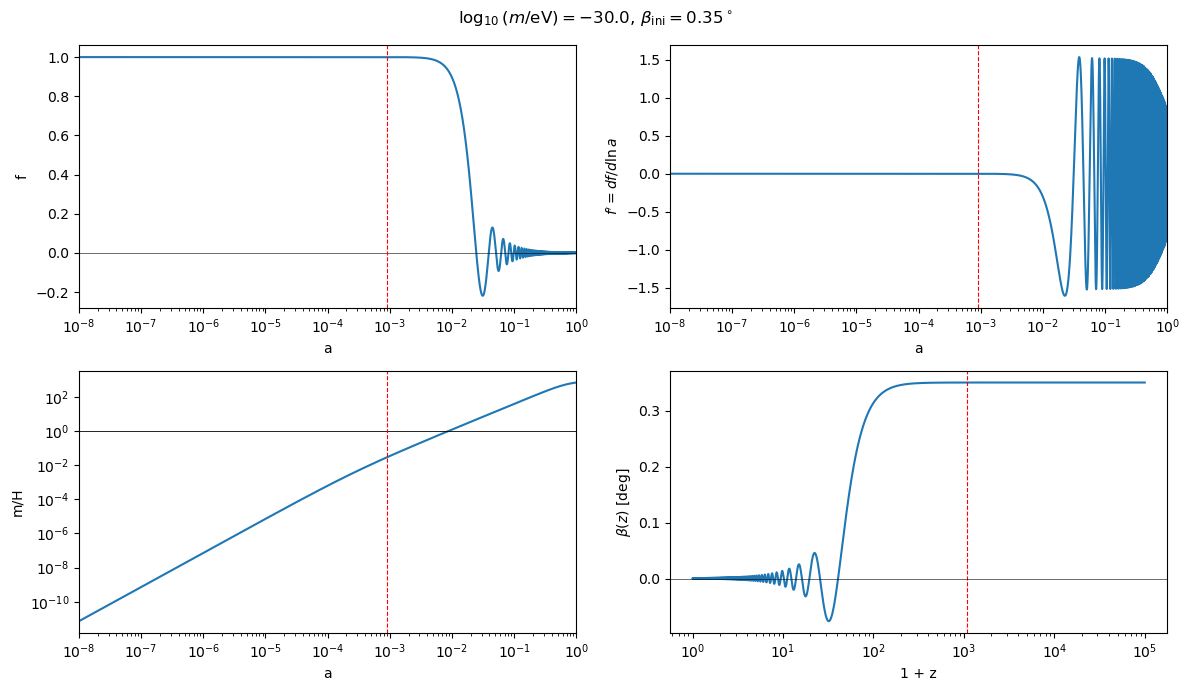

interactive(children=(FloatSlider(value=-30.0, description='log_m', max=-26.0, min=-35.0), FloatSlider(value=0…

In [14]:
def explore(log_m, beta_ini=0.35):
    m = 10**log_m
    s, xe, f0 = solve_axion_field(bg, m)
    xx = np.linspace(np.log(1e-8), xe, 20000); a = np.exp(xx); y = s(xx)
    mH = m / hubble_ev(bg, np.exp(-xx) - 1)
    z, b = axion_birefringence_table(pars, m, beta_ini, results=bg)
    print(f"log m = {log_m}: m/H0 = {m / H0_ev:.2e}, f(0) = {f0:+.3e}, "
          f"stop at {'z = %.2f' % (np.exp(-xe) - 1) if xe < -1e-12 else 'today (never reached m/H = 1000)'}")
    print(f"beta(z) [deg]: z=1090: {np.interp(1090, z, b):+.4e}, z=10: {np.interp(10, z, b):+.4e}, "
          f"z=1: {np.interp(1, z, b):+.4e}")
    fig, ax = plt.subplots(2, 2, figsize=(12, 7))
    ax[0, 0].semilogx(a, y[0]); ax[0, 0].set_ylabel("f"); ax[0, 0].axhline(0, color="k", lw=0.4)
    ax[0, 1].semilogx(a, y[1]); ax[0, 1].set_ylabel(r"$f' = df/d\ln a$")
    ax[1, 0].loglog(a, mH); ax[1, 0].axhline(1, color="k", lw=0.6); ax[1, 0].set_ylabel("m/H")
    for a_ in (ax[0, 0], ax[0, 1], ax[1, 0]):
        a_.set_xlim(1e-8, 1); a_.set_xlabel("a"); a_.axvline(1 / 1091, color="r", ls="--", lw=0.8)
    ax[1, 1].semilogx(1 + z, b); ax[1, 1].set_xlabel("1 + z"); ax[1, 1].set_ylabel(r"$\beta(z)$ [deg]")
    ax[1, 1].axvline(1091, color="r", ls="--", lw=0.8); ax[1, 1].axhline(0, color="k", lw=0.4)
    fig.suptitle(rf"$\log_{{10}}(m/{{\rm eV}}) = {log_m}$, $\beta_{{\rm ini}} = {beta_ini}^\circ$")
    plt.tight_layout(); plt.show()

explore(-28.0)

try:
    from ipywidgets import interact, FloatSlider
    interact(explore, log_m=FloatSlider(value=-30.0, min=-35, max=-26, step=0.1), beta_ini=(0.05, 1.0, 0.05))
except ImportError:
    print("ipywidgets not installed: call explore(log_m) with the mass you want, e.g. explore(-31.5)")

## 7. What the CMB sees: EB for a few masses

Each template is normalised so that $\beta(z_{\rm rec}) = 0.35^\circ$, which makes the light masses comparable with
the constant-$\beta$ case (dashed). This runs CAMB once per mass (about 10 s each).

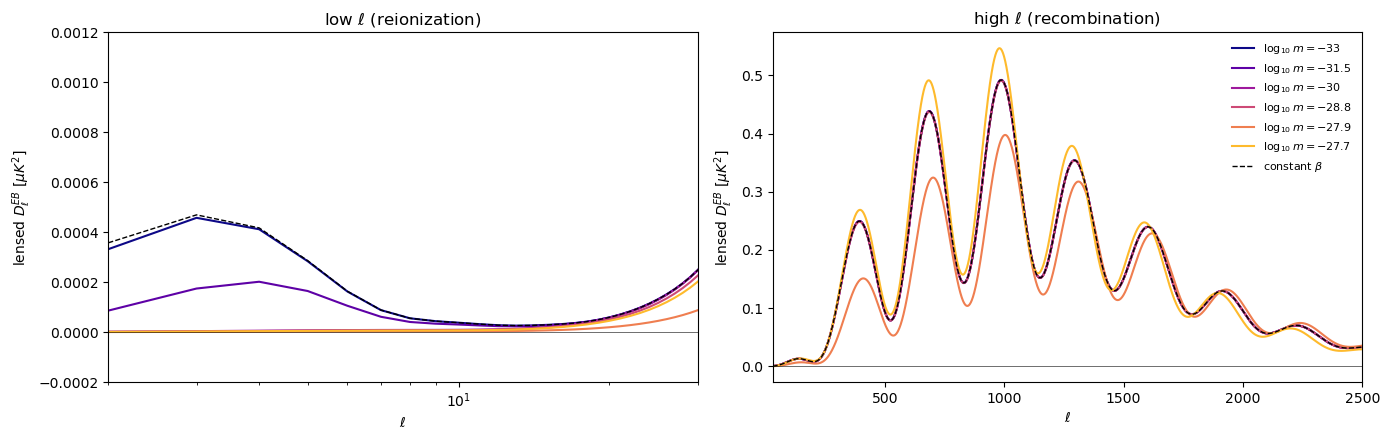

In [7]:
def eb_cls(table=None, angle=0.0, lmax=2500):
    p = camb.set_params(**cosmo, lmax=lmax, lSampleBoost=50, AccuracyBoost=2, birefringence_angle=angle)
    if table is not None:
        p.set_birefringence_table(*table)
    return camb.get_results(p).get_birefringence_cls(CMB_unit="muK", lensed=True)[:lmax + 1, 4]

target = 0.35
eb_const = eb_cls(angle=target)
ell = np.arange(eb_const.size)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for lm, c in zip([-33, -31.5, -30, -28.8, -27.9, -27.7], plt.cm.plasma(np.linspace(0, 0.85, 6))):
    z, b = axion_birefringence_table(pars, 10**lm, 1.0, results=bg)
    e = eb_cls((z, b * target / np.interp(1090, z, b)))
    for a_ in ax:
        a_.plot(ell[2:], e[2:], color=c, label=rf"$\log_{{10}} m = {lm}$")
for a_ in ax:
    a_.plot(ell[2:], eb_const[2:], "k--", lw=1, label=r"constant $\beta$")
    a_.axhline(0, color="k", lw=0.4); a_.set_xlabel(r"$\ell$"); a_.set_ylabel(r"lensed $D_\ell^{EB}\ [\mu K^2]$")
ax[0].set_xscale("log"); ax[0].set_xlim(2, 30); ax[0].set_ylim(-2e-4, 1.2e-3); ax[0].set_title(r"low $\ell$ (reionization)")
ax[1].set_xlim(30, 2500); ax[1].set_title(r"high $\ell$ (recombination)"); ax[1].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()